<a href="https://colab.research.google.com/github/muiddd/5thSemester_MachineLearning/blob/main/01_AbdulMuid_P7.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Week 7: ANN (Approximate Nearest Neighbors)**

* **Nama:** Abdul Muid
* **NIM:** 244107020006
* **Kelas:** TI 3A
* **Mata Kuliah:** Machine Learning

---

## **Praktikum 1**

In [1]:
!pip install annoy

Exact NN index: [219 898 593]
Exact NN jarak: [0.         1.36915938 2.27931544]
Waktu Exact: 9.768 ms

Annoy NN index: [219, 898, 770]
Annoy NN jarak: [np.float64(0.0), np.float64(1.369159376273702), np.float64(2.568167959732514)]
Waktu Annoy: 0.1183 ms


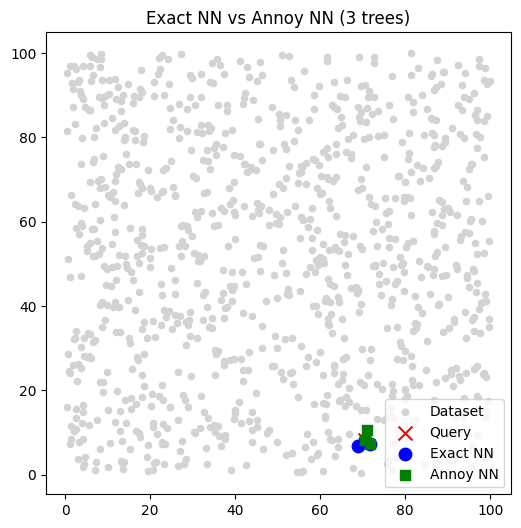

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import time

from annoy import AnnoyIndex

# 1. Dataset 2D
np.random.seed(42)
n_points = 1000
X = np.random.rand(n_points, 2) * 100  # titik random dalam ruang 100x100

# Query point (ambil salah satu titik random)
query = X[np.random.randint(0, n_points)]

# 2. Exact NN (brute force)
start = time.time()
distances = np.linalg.norm(X - query, axis=1)
idx_exact = np.argsort(distances)[:3]  # ambil 3 terdekat
time_exact = time.time() - start

print("Exact NN index:", idx_exact)
print("Exact NN jarak:", distances[idx_exact])
print("Waktu Exact:", round(time_exact*1000, 4), "ms")

# 3. Annoy NN (3 tree)
f = 2  # dimensi
t = AnnoyIndex(f, 'euclidean')
for i, vec in enumerate(X):
    t.add_item(i, vec)

t.build(3)  # 3 trees

start = time.time()
idx_ann = t.get_nns_by_vector(query, 3)  # cari 3 NN
time_ann = time.time() - start

print("\nAnnoy NN index:", idx_ann)
print("Annoy NN jarak:", [np.linalg.norm(X[i]-query) for i in idx_ann])
print("Waktu Annoy:", round(time_ann*1000, 4), "ms")

# 4. Visualisasi hasil
plt.figure(figsize=(6,6))
plt.scatter(X[:,0], X[:,1], c="lightgray", s=20, label="Dataset")
plt.scatter(query[0], query[1], c="red", marker="x", s=100, label="Query")

# Exact NN ditandai biru
plt.scatter(X[idx_exact,0], X[idx_exact,1], c="blue", s=80, label="Exact NN")

# Annoy NN ditandai hijau
plt.scatter(X[idx_ann,0], X[idx_ann,1], c="green", s=50, marker="s", label="Annoy NN")

plt.legend()
plt.title("Exact NN vs Annoy NN (3 trees)")
plt.show()

In [2]:
!pip install -q annoy
import numpy as np
import pandas as pd
import time
from annoy import AnnoyIndex

def run_experiment():
    # List skenario parameter
    skenario = [
        {'metric': 'euclidean', 'trees': 8, 'n_data': 1000},
        {'metric': 'euclidean', 'trees': 3, 'n_data': 100000},
        {'metric': 'angular', 'trees': 3, 'n_data': 1000},
        {'metric': 'angular', 'trees': 8, 'n_data': 1000},
        {'metric': 'angular', 'trees': 3, 'n_data': 100000}
    ]

    hasil_eksperimen = []

    for param in skenario:
        metric = param['metric']
        trees = param['trees']
        n_data = param['n_data']

        # 1. Generate dataset random 2D
        np.random.seed(42)
        X = np.random.rand(n_data, 2).astype(np.float32) * 100.0

        # Pilih satu query point secara acak dari dataset
        query_idx = np.random.randint(0, n_data)
        query = X[query_idx]

        # 2. Exact NN (ENN)
        start_enn = time.time()
        if metric == 'euclidean':
            distances = np.linalg.norm(X - query, axis=1)
        elif metric == 'angular':
            # Normalisasi L2 untuk angular distance / cosine distance
            norm_X = np.linalg.norm(X, axis=1, keepdims=True)
            norm_X[norm_X == 0] = 1.0  # hindari pembagian nol
            X_normalized = X / norm_X

            norm_query = np.linalg.norm(query)
            query_normalized = query / (norm_query if norm_query > 0 else 1.0)

            # Cosine distance = 1 - cosine similarity
            cosine_sim = np.dot(X_normalized, query_normalized)
            distances = 1.0 - cosine_sim

        idx_enn = np.argsort(distances)[:3].tolist()
        time_enn = time.time() - start_enn

        # 3. Annoy NN (ANN)
        f = 2  # dimensi
        t = AnnoyIndex(f, metric)
        for i, vec in enumerate(X):
            t.add_item(i, vec)
        t.build(trees)

        start_ann = time.time()
        idx_ann = t.get_nns_by_vector(query, 3)
        time_ann = time.time() - start_ann

        # Format hasil index
        hasil_index = f"ENN: {idx_enn} vs ANN: {idx_ann}"

        # Format waktu komputasi
        waktu_vs = f"ENN: {round(time_enn * 1000, 4)} ms vs ANN: {round(time_ann * 1000, 4)} ms"

        # Simpan ke list hasil
        hasil_eksperimen.append({
            'Distance Metrics': metric.capitalize(),
            'Tree': trees,
            'Jumlah data': f"{(n_data):,}",
            'Hasil Index terdekat ENN vs ANN': hasil_index,
            'Waktu komputasi Vs': waktu_vs
        })

    # Ubah menjadi DataFrame
    df = pd.DataFrame(hasil_eksperimen)
    return df

# Jalankan eksperimen dan tampilkan tabel
df_hasil = run_experiment()
df_hasil

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 647.5/647.5 kB 10.8 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done


,Distance Metrics,Tree,Jumlah data,Hasil Index terdekat ENN vs ANN,Waktu komputasi Vs
0,Euclidean,8,"1,000","ENN: [219, 898, 593] vs ANN: [219, 898, 593]",ENN: 11.4474 ms vs ANN: 0.0534 ms
1,Euclidean,3,"100,000","ENN: [64040, 64186, 88792] vs ANN: [64040, 641...",ENN: 10.2978 ms vs ANN: 0.0465 ms
2,Angular,3,"1,000","ENN: [219, 429, 540] vs ANN: [219, 429, 540]",ENN: 0.7865 ms vs ANN: 0.0296 ms
3,Angular,8,"1,000","ENN: [219, 429, 540] vs ANN: [219, 429, 540]",ENN: 0.2537 ms vs ANN: 0.0451 ms
4,Angular,3,"100,000","ENN: [25236, 44528, 5576] vs ANN: [7452, 9720,...",ENN: 9.7311 ms vs ANN: 0.0367 ms


In [3]:
import numpy as np
import time
from sklearn.metrics.pairwise import euclidean_distances
from annoy import AnnoyIndex

# ---- 1. Buat dataset mirip Spotify ----
n_tracks = 5_000_000   # 5 juta track
n_features = 20        # contoh: danceability, energy, tempo, dll.

# dataset besar (random untuk simulasi)
X = np.random.rand(n_tracks, n_features).astype(np.float32)

# query track (misalnya lagu baru)
query = np.random.rand(1, n_features).astype(np.float32)

# ---- 2. Exact NN (brute force) ----
start = time.time()
distances = euclidean_distances(query, X)[0]   # hitung semua jarak
exact_idx = np.argsort(distances)[:5]          # ambil 5 terdekat
exact_time = time.time() - start

print("Exact NN result:", exact_idx)
print("Exact NN time:", round(exact_time, 3), "seconds")

# ---- 3. Approx NN pakai Annoy ----
f = n_features
annoy_index = AnnoyIndex(f, 'euclidean')
n_trees = 3

# build index
for i in range(n_tracks):
    annoy_index.add_item(i, X[i])
annoy_index.build(n_trees)

start = time.time()
annoy_idx = annoy_index.get_nns_by_vector(query[0], 5)  # ambil 5 lagu yang mirip
annoy_time = time.time() - start

print("Annoy result:", annoy_idx)
print("Annoy time:", round(annoy_time, 3), "seconds")


Exact NN result: [2354103  376853 4943356 4785851  892857]
Exact NN time: 0.921 seconds
Annoy result: [1776462, 4102636, 1964951, 1423347, 3620753]
Annoy time: 0.0 seconds


**Pertanyaannya: Kenapa code dibagian build index tidak dihitung waktunya?**


Proses build index merupakan tahap persiapan awal (pre-processing) yang hanya perlu dilakukan sekali sebelum sistem berjalan. Oleh karena itu, perhitungan hanya difokuskan pada waktu pencarian (query time) untuk melihat seberapa cepat algoritma tersebut merespons pencarian secara real-time.

## **Praktikum 2**

In [4]:
!pip install faiss-cpu
#!pip install faiss-gpu

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 18.8/18.8 MB 70.5 MB/s eta 0:00:00


Exact NN (Flat) indices: [[137 170 750]] distances: [[0.00013095 0.00077404 0.00079751]]
IVF+PQ indices: [[137 170 750]] distances: [[0.00012945 0.00079226 0.00080067]]
Waktu Exact: 0.00019550323486328125
Waktu IVF+PQ: 0.00019550323486328125


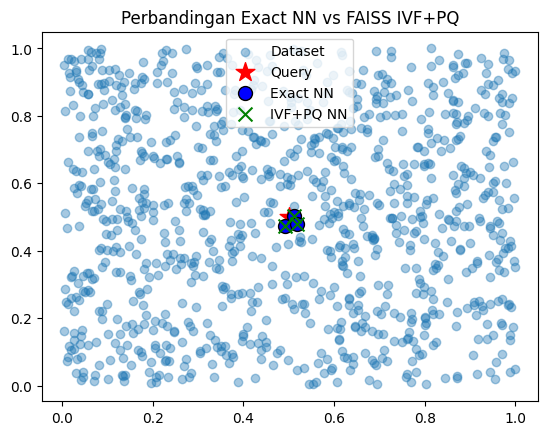

In [5]:
import numpy as np
import faiss
import matplotlib.pyplot as plt
import time

# 1. Buat dataset 2D sederhana
np.random.seed(42)
X = np.random.rand(1000, 2).astype('float32')  # 1000 titik 2D
query = np.array([[0.5, 0.5]], dtype='float32')  # query di tengah

# 2. Exact NN dengan IndexFlatL2 (brute force tapi cepat)
index_flat = faiss.IndexFlatL2(2)   # L2 = Euclidean distance
index_flat.add(X)

start = time.time()
D_flat, I_flat = index_flat.search(query, 3)  # cari 3 tetangga terdekat
end = time.time()
time_flat = end - start

# 3. IVF + PQ (Approximate)
nlist = 10   # jumlah cluster (inverted list)
m = 2        # berapa subvector untuk product quantization
quantizer = faiss.IndexFlatL2(2)   # dipakai IVF untuk cluster awal
index_ivfpq = faiss.IndexIVFPQ(quantizer, 2, nlist, m, 8)  # 8 bit per subvector

index_ivfpq.train(X)  # training centroid
index_ivfpq.add(X)

start = time.time()
D_ivfpq, I_ivfpq = index_ivfpq.search(query, 3)
end = time.time()
time_ivfpq = end - start

# 4. Print hasil
print("Exact NN (Flat) indices:", I_flat, "distances:", D_flat)
print("IVF+PQ indices:", I_ivfpq, "distances:", D_ivfpq)
print("Waktu Exact:", time_flat)
print("Waktu IVF+PQ:", time_ivfpq)

# 5. Visualisasi
plt.scatter(X[:,0], X[:,1], alpha=0.4, label="Dataset")
plt.scatter(query[:,0], query[:,1], c='red', marker='*', s=200, label="Query")

# Tetangga dari Flat
plt.scatter(X[I_flat[0],0], X[I_flat[0],1], c='blue', s=100, edgecolor='k', label="Exact NN")

# Tetangga dari IVF+PQ
plt.scatter(X[I_ivfpq[0],0], X[I_ivfpq[0],1], c='green', marker='x', s=100, label="IVF+PQ NN")

plt.legend()
plt.title("Perbandingan Exact NN vs FAISS IVF+PQ")
plt.show()


In [6]:
import numpy as np
import faiss
import time
import pandas as pd

# Siapkan list untuk menyimpan hasil
hasil_eksperimen = []

# Skenario parameter yang akan diuji
skenario_data = [1000, 1_000_000]
skenario_dimensi = [2, 5]
skenario_metric = ['L2 (Euclidean)', 'Inner Product']

np.random.seed(42)
print("Menjalankan eksperimen FAISS, harap tunggu beberapa saat...\n")

for n_data in skenario_data:
    for dim in skenario_dimensi:
        for metric in skenario_metric:
            # 1. Generate Dataset & Query
            X = np.random.rand(n_data, dim).astype('float32')
            query = np.random.rand(1, dim).astype('float32')

            # Normalisasi L2 pada dataset jika menggunakan Inner Product (menjadi Cosine Similarity)
            if metric == 'Inner Product':
                faiss.normalize_L2(X)
                faiss.normalize_L2(query)

            # 2. EXACT NN (Flat / Brute Force)
            start_exact = time.time()
            if metric == 'L2 (Euclidean)':
                index_exact = faiss.IndexFlatL2(dim)
            else:
                index_exact = faiss.IndexFlatIP(dim)

            index_exact.add(X)
            D_exact, I_exact = index_exact.search(query, 3)
            waktu_exact = time.time() - start_exact

            # 3. APPROXIMATE NN (IVF+PQ)
            # Syarat PQ: m harus merupakan pembagi habis dari dimensi (dim % m == 0)
            m = dim # Set m sama dengan dimensi (m=2 untuk 2D, m=5 untuk 5D)
            nlist = 10 if n_data == 1000 else 100 # Jumlah cluster (lebih banyak untuk 1 juta data)

            start_ivfpq = time.time()
            if metric == 'L2 (Euclidean)':
                quantizer = faiss.IndexFlatL2(dim)
                index_ivfpq = faiss.IndexIVFPQ(quantizer, dim, nlist, m, 8)
            else:
                quantizer = faiss.IndexFlatIP(dim)
                # Menambahkan parameter metrik ke IVF
                index_ivfpq = faiss.IndexIVFPQ(quantizer, dim, nlist, m, 8, faiss.METRIC_INNER_PRODUCT)

            index_ivfpq.train(X)
            index_ivfpq.add(X)
            D_ivfpq, I_ivfpq = index_ivfpq.search(query, 3)
            waktu_ivfpq = time.time() - start_ivfpq

            # 4. Simpan hasil iterasi ke dalam list
            hasil_eksperimen.append({
                "Jumlah Data": f"{n_data:,}",
                "Dimensi": f"{dim}D",
                "Metrik Jarak": metric,
                "Waktu Exact (detik)": round(waktu_exact, 5),
                "Waktu IVF+PQ (detik)": round(waktu_ivfpq, 5)
            })

# Tampilkan hasil dalam bentuk tabel interaktif Pandas
df_hasil = pd.DataFrame(hasil_eksperimen)
display(df_hasil)

Menjalankan eksperimen FAISS, harap tunggu beberapa saat...



,Jumlah Data,Dimensi,Metrik Jarak,Waktu Exact (detik),Waktu IVF+PQ (detik)
0,"1,000",2D,L2 (Euclidean),0.00016,0.23460
1,"1,000",2D,Inner Product,0.00011,0.07831
2,"1,000",5D,L2 (Euclidean),0.00009,0.17368
3,"1,000",5D,Inner Product,0.00011,0.41799
4,"1,000,000",2D,L2 (Euclidean),0.01977,11.09397
5,"1,000,000",2D,Inner Product,0.00468,9.94824
6,"1,000,000",5D,L2 (Euclidean),0.01505,22.44190
7,"1,000,000",5D,Inner Product,0.02475,22.54527


## **Praktikum 3**

In [1]:
!pip install hnswlib

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Created wheel for hnswlib: filename=hnswlib-0.8.0-cp313-cp313-linux_x86_64.whl size=2679800 sha256=9ce025f755e6b2e09ddbb8a491bde6229deed8ea343f69a3e5b5cbe0e479d668
  Stored in directory: /root/.cache/pip/wheels/35/04/88/b31765a4b9957705e18065db4657e61fc8da54f50e3ef0b67e
Successfully built hnswlib


In [2]:
import hnswlib
import numpy as np
import time
from sklearn.neighbors import NearestNeighbors

# ===========================
# 1. Buat data 2D acak
# ===========================
num_elements = 1000
dim = 2
data = np.random.random((num_elements, dim)).astype(np.float32)

# Query point
query = np.array([[0.5, 0.5]], dtype=np.float32)
k = 5  # cari 5 tetangga terdekat

# ===========================
# 2. Exact NN (Brute Force)
# ===========================
nn = NearestNeighbors(n_neighbors=k, algorithm='brute', metric='euclidean')
nn.fit(data)

start = time.time()
distances, indices = nn.kneighbors(query)
end = time.time()

print("=== Exact NN ===")
print("Indices:", indices)
print("Distances:", distances)
print("Waktu:", end - start, "detik")

# ===========================
# 3. HNSW
# ===========================
# Inisialisasi index HNSW
p = hnswlib.Index(space='l2', dim=dim)

# Ukuran maksimum elemen yang bisa ditampung
p.init_index(max_elements=num_elements, ef_construction=100, M=16)

# Tambahkan data
p.add_items(data)

# Set parameter pencarian
p.set_ef(50)   # tradeoff speed vs accuracy

start = time.time()
labels, distances = p.knn_query(query, k=k)
end = time.time()

print("\n=== HNSW ===")
print("Indices:", labels)
print("Distances:", distances)
print("Waktu:", end - start, "detik")


=== Exact NN ===
Indices: [[810 753 191 171 268]]
Distances: [[0.00976358 0.01956958 0.0439254  0.05098112 0.05433162]]
Waktu: 0.05891013145446777 detik

=== HNSW ===
Indices: [[810 753 191 171 268]]
Distances: [[9.5327392e-05 3.8296831e-04 1.9294412e-03 2.5990745e-03 2.9519247e-03]]
Waktu: 0.00028395652770996094 detik


In [3]:
import numpy as np
import pandas as pd
import time
import hnswlib
from sklearn.neighbors import NearestNeighbors

def run_hnsw_vs_exact_experiment():
    # List kombinasi parameter
    metrik_list = ['l2', 'cosine']
    jumlah_data_list = [1000, 1000000]
    dimensi_list = [2, 5]

    hasil_eksperimen = []
    k = 5

    np.random.seed(42)
    print("Memulai eksperimen perbandingan HNSW vs Exact NN... Harap tunggu.\n")

    for metric in metrik_list:
        for n_data in jumlah_data_list:
            for dim in dimensi_list:
                # 1. Bangkitkan dataset acak dan 1 titik query
                data = np.random.random((n_data, dim)).astype(np.float32)
                query = np.random.random((1, dim)).astype(np.float32)

                # 2. EXACT NN (Brute Force dengan scikit-learn)
                # Map metrik l2 ke euclidean untuk sklearn
                sklearn_metric = 'euclidean' if metric == 'l2' else 'cosine'
                nn_exact = NearestNeighbors(n_neighbors=k, algorithm='brute', metric=sklearn_metric)
                nn_exact.fit(data)

                # Ambil waktu pencarian query saja
                start_exact = time.time()
                _, _ = nn_exact.kneighbors(query)
                time_exact = time.time() - start_exact

                # 3. HNSW (menggunakan hnswlib)
                p_hnsw = hnswlib.Index(space=metric, dim=dim)

                # Konfigurasi standard
                p_hnsw.init_index(max_elements=n_data, ef_construction=100, M=16)
                p_hnsw.add_items(data)
                p_hnsw.set_ef(50)  # tradeoff speed vs accuracy

                # Ambil waktu pencarian query saja
                start_hnsw = time.time()
                _, _ = p_hnsw.knn_query(query, k=k)
                time_hnsw = time.time() - start_hnsw

                # Simpan hasil
                hasil_eksperimen.append({
                    'Metrik': 'Euclidean (L2)' if metric == 'l2' else 'Cosine',
                    'Jumlah Data': f"{n_data:,}",
                    'Dimensi': f"{dim}D",
                    'Waktu Exact NN (detik)': round(time_exact, 7),
                    'Waktu HNSW (detik)': round(time_hnsw, 7)
                })

    df_hasil = pd.DataFrame(hasil_eksperimen)
    return df_hasil

# Jalankan fungsi eksperimen dan tampilkan tabel
df_tabel = run_hnsw_vs_exact_experiment()
display(df_tabel)

Memulai eksperimen perbandingan HNSW vs Exact NN... Harap tunggu.



,Metrik,Jumlah Data,Dimensi,Waktu Exact NN (detik),Waktu HNSW (detik)
0,Euclidean (L2),"1,000",2D,0.001167,0.000090
1,Euclidean (L2),"1,000",5D,0.005071,0.000098
2,Euclidean (L2),"1,000,000",2D,0.144992,0.000182
3,Euclidean (L2),"1,000,000",5D,0.034185,0.000217
4,Cosine,"1,000",2D,0.014746,0.000079
5,Cosine,"1,000",5D,0.001574,0.000092
6,Cosine,"1,000,000",2D,0.035201,0.000215
7,Cosine,"1,000,000",5D,0.046629,0.000141


## **Praktikum 4**

In [6]:
!pip install -q annoy faiss-cpu

import numpy as np
import time
from annoy import AnnoyIndex
import faiss
import hnswlib

# ===============================
# 1. Buat dataset 1 juta data 5D
# ===============================
n_data = 1_000_000   # bisa coba 100_000 dulu jika RAM terbatas
dim = 5
X = np.random.random((n_data, dim)).astype(np.float32)

# Query point
query = np.random.random((1, dim)).astype(np.float32)
k = 10

# ===============================
# 2. Annoy
# ===============================
print("=== Annoy ===")
ann_index = AnnoyIndex(dim, 'euclidean')

start = time.time()
for i in range(n_data):
    ann_index.add_item(i, X[i])
ann_index.build(10)  # 10 trees
build_time = time.time() - start

start = time.time()
neighbors = ann_index.get_nns_by_vector(query[0], k, include_distances=True)
query_time = time.time() - start

print("Build time:", build_time, "detik")
print("Query time:", query_time, "detik")
print("Neighbors:", neighbors[0][:5], "...")

# ===============================
# 3. FAISS (Flat Index)
# ===============================
print("\n=== FAISS (IndexFlatL2) ===")
faiss_index = faiss.IndexFlatL2(dim)

start = time.time()
faiss_index.add(X)
build_time = time.time() - start

start = time.time()
distances, indices = faiss_index.search(query, k)
query_time = time.time() - start

print("Build time:", build_time, "detik")
print("Query time:", query_time, "detik")
print("Neighbors:", indices[0][:5], "...")

# ===============================
# 4. HNSW (hnswlib)
# ===============================
print("\n=== HNSW (hnswlib) ===")
hnsw_index = hnswlib.Index(space='l2', dim=dim)

start = time.time()
hnsw_index.init_index(max_elements=n_data, ef_construction=200, M=16)
hnsw_index.add_items(X)
build_time = time.time() - start

hnsw_index.set_ef(50)

start = time.time()
labels, distances = hnsw_index.knn_query(query, k=k)
query_time = time.time() - start

print("Build time:", build_time, "detik")
print("Query time:", query_time, "detik")
print("Neighbors:", labels[0][:5], "...")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 18.8/18.8 MB 16.7 MB/s eta 0:00:00
=== Annoy ===
Build time: 22.84017586708069 detik
Query time: 0.000225067138671875 detik
Neighbors: [968151, 819015, 152491, 752066, 63130] ...

=== FAISS (IndexFlatL2) ===
Build time: 0.007861614227294922 detik
Query time: 0.010008811950683594 detik
Neighbors: [968151 819015 152491 752066  63130] ...

=== HNSW (hnswlib) ===
Build time: 176.5117084980011 detik
Query time: 0.0004115104675292969 detik
Neighbors: [968151 819015 152491 752066  63130] ...


In [7]:
import numpy as np
import pandas as pd
import time
import hnswlib
from sklearn.neighbors import NearestNeighbors

def run_benchmark():
    # Parameter kombinasi
    metrics = ['l2', 'cosine']
    data_sizes = [1000, 1000000]
    dimensions = [2, 5]
    k = 5

    hasil_list = []

    for metric in metrics:
        for n_data in data_sizes:
            for dim in dimensions:
                # 1. Bangkitkan dataset dan 1 titik query secara acak
                np.random.seed(42)
                data = np.random.random((n_data, dim)).astype(np.float32)
                query = np.random.random((1, dim)).astype(np.float32)

                # 2. Exact NN (Brute Force via sklearn)
                metric_sklearn = 'euclidean' if metric == 'l2' else 'cosine'
                model_exact = NearestNeighbors(n_neighbors=k, algorithm='brute', metric=metric_sklearn)
                model_exact.fit(data)

                start_exact = time.time()
                _, _ = model_exact.kneighbors(query)
                time_exact = time.time() - start_exact

                # 3. HNSW (via hnswlib)
                p_hnsw = hnswlib.Index(space=metric, dim=dim)
                p_hnsw.init_index(max_elements=n_data, ef_construction=100, M=16)
                p_hnsw.add_items(data)
                p_hnsw.set_ef(50)

                start_hnsw = time.time()
                _, _ = p_hnsw.knn_query(query, k=k)
                time_hnsw = time.time() - start_hnsw

                # Simpan hasil
                hasil_list.append({
                    'Metrik': 'Euclidean (l2)' if metric == 'l2' else 'Cosine',
                    'Jumlah Data': f"{n_data:,}",
                    'Dimensi': f"{dim}D",
                    'Waktu Exact NN (detik)': time_exact,
                    'Waktu HNSW (detik)': time_hnsw
                })

    df_hasil = pd.DataFrame(hasil_list)
    return df_hasil

# Menampilkan hasil langsung
df_tabel_tugas = run_benchmark()
df_tabel_tugas

,Metrik,Jumlah Data,Dimensi,Waktu Exact NN (detik),Waktu HNSW (detik)
0,Euclidean (l2),"1,000",2D,0.001431,0.000106
1,Euclidean (l2),"1,000",5D,0.000654,0.000103
2,Euclidean (l2),"1,000,000",2D,0.027065,0.000131
3,Euclidean (l2),"1,000,000",5D,0.031486,0.000171
4,Cosine,"1,000",2D,0.002497,0.000067
5,Cosine,"1,000",5D,0.001666,0.000139
6,Cosine,"1,000,000",2D,0.032099,0.000127
7,Cosine,"1,000,000",5D,0.082632,0.000217


## **Praktikum 5**

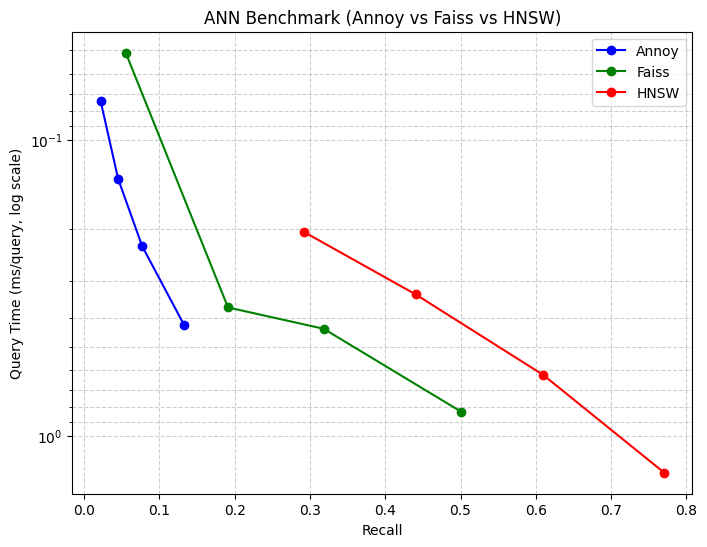

In [8]:
import numpy as np
import time
import faiss
from annoy import AnnoyIndex
import hnswlib
import matplotlib.pyplot as plt

# -------------------------------
# Dataset random
# -------------------------------
d = 128        # dimensi
nb = 100000    # jumlah database vector
nq = 1000      # jumlah query

np.random.seed(42)
xb = np.random.random((nb, d)).astype('float32')
xq = np.random.random((nq, d)).astype('float32')

# -------------------------------
# Ground truth dengan FAISS brute force
# -------------------------------
index_flat = faiss.IndexFlatL2(d)
index_flat.add(xb)
k = 10
_, gt_idx = index_flat.search(xq, k)

# -------------------------------
# Fungsi recall
# -------------------------------
def recall_at_k(I_pred, I_gt, k):
    correct = 0
    for i in range(len(I_pred)):
        correct += len(set(I_pred[i][:k]) & set(I_gt[i][:k]))
    return correct / (len(I_pred) * k)

# -------------------------------
# Benchmark Annoy
# -------------------------------
def run_annoy(xb, xq, n_trees=10, search_k=1000, k=10):
    f = xb.shape[1]
    index = AnnoyIndex(f, 'euclidean')
    for i, v in enumerate(xb):
        index.add_item(i, v)
    index.build(n_trees)

    start = time.time()
    I = [index.get_nns_by_vector(v, k, search_k=search_k) for v in xq]
    elapsed = (time.time() - start) * 1000 / len(xq)  # ms/query
    rec = recall_at_k(I, gt_idx, k)
    return rec, elapsed

# -------------------------------
# Benchmark FAISS IVF
# -------------------------------
def run_faiss(xb, xq, nlist=100, nprobe=10, k=10):
    quantizer = faiss.IndexFlatL2(d)
    index = faiss.IndexIVFFlat(quantizer, d, nlist, faiss.METRIC_L2)
    index.train(xb)
    index.add(xb)

    index.nprobe = nprobe
    start = time.time()
    _, I = index.search(xq, k)
    elapsed = (time.time() - start) * 1000 / len(xq)
    rec = recall_at_k(I, gt_idx, k)
    return rec, elapsed

# -------------------------------
# Benchmark HNSW
# -------------------------------
def run_hnsw(xb, xq, ef=100, M=16, k=10):
    num_elements = xb.shape[0]
    p = hnswlib.Index(space='l2', dim=d)
    p.init_index(max_elements=num_elements, ef_construction=200, M=M)
    p.add_items(xb)
    p.set_ef(ef)

    start = time.time()
    I, _ = p.knn_query(xq, k)
    elapsed = (time.time() - start) * 1000 / len(xq)
    rec = recall_at_k(I, gt_idx, k)
    return rec, elapsed

# -------------------------------
# Jalankan benchmark dengan beberapa parameter
# -------------------------------
results = {"Annoy": [], "Faiss": [], "HNSW": []}

# Annoy
for sk in [200, 500, 1000, 2000]:
    rec, t = run_annoy(xb, xq, n_trees=10, search_k=sk)
    results["Annoy"].append((rec, t))

# FAISS
for npb in [1, 5, 10, 20]:
    rec, t = run_faiss(xb, xq, nlist=100, nprobe=npb)
    results["Faiss"].append((rec, t))

# HNSW
for ef in [50, 100, 200, 400]:
    rec, t = run_hnsw(xb, xq, ef=ef)
    results["HNSW"].append((rec, t))

# -------------------------------
# Visualisasi trade-off
# -------------------------------
plt.figure(figsize=(8,6))
for label, color in zip(results.keys(), ["blue","green","red"]):
    recall, qtime = zip(*results[label])
    plt.plot(recall, qtime, marker="o", label=label, color=color)

plt.xlabel("Recall")
plt.ylabel("Query Time (ms/query, log scale)")
plt.yscale("log")
plt.gca().invert_yaxis()  # invert Y, makin kanan makin turun
plt.title("ANN Benchmark (Annoy vs Faiss vs HNSW)")
plt.legend()
plt.grid(True, which="both", ls="--", alpha=0.6)
plt.show()

## **Praktikum 6**

In [15]:
import pandas as pd
import numpy as np
import time
import faiss
from annoy import AnnoyIndex
import hnswlib
from sklearn.neighbors import NearestNeighbors
from sklearn.preprocessing import StandardScaler

# -------------------------------
# Load dataset
# -------------------------------

df = pd.read_csv('/content/songs_with_attributes_and_lyrics.csv',
                 encoding='utf-8-sig',
                 on_bad_lines='skip',
                 engine='python')
features = ['danceability', 'energy', 'loudness', 'speechiness',
            'acousticness', 'instrumentalness', 'liveness', 'valence', 'tempo']
X = df[features].values

# Standarisasi fitur
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

k = 10  # jumlah nearest neighbors

# -------------------------------
# Exact Nearest Neighbor (brute-force)
# -------------------------------
start = time.time()
nn = NearestNeighbors(n_neighbors=k, algorithm='brute', metric='euclidean')
nn.fit(X_scaled)
dist_exact, idx_exact = nn.kneighbors(X_scaled)
time_exact = time.time() - start
print(f"Exact NN done in {time_exact:.3f} s")

# -------------------------------
# Annoy
# -------------------------------
start = time.time()
f = X_scaled.shape[1]
index_annoy = AnnoyIndex(f, 'euclidean')
for i, v in enumerate(X_scaled):
    index_annoy.add_item(i, v)
index_annoy.build(10)
idx_annoy = [index_annoy.get_nns_by_vector(v, k) for v in X_scaled]
time_annoy = time.time() - start
print(f"Annoy done in {time_annoy:.3f} s")

# -------------------------------
# HNSW
# -------------------------------
start = time.time()
p_hnsw = hnswlib.Index(space='l2', dim=X_scaled.shape[1])
p_hnsw.init_index(max_elements=X_scaled.shape[0], ef_construction=200, M=16)
p_hnsw.add_items(X_scaled)
p_hnsw.set_ef(200)
idx_hnsw, dist_hnsw = p_hnsw.knn_query(X_scaled, k=k)
time_hnsw = time.time() - start
print(f"HNSW done in {time_hnsw:.3f} s")

# -------------------------------
# FAISS IVF
# -------------------------------
start = time.time()
quantizer = faiss.IndexFlatL2(X_scaled.shape[1])
index_faiss = faiss.IndexIVFFlat(quantizer, X_scaled.shape[1], 100, faiss.METRIC_L2)
index_faiss.train(X_scaled)
index_faiss.add(X_scaled)
index_faiss.nprobe = 10
dist_faiss, idx_faiss = index_faiss.search(X_scaled, k)
time_faiss = time.time() - start
print(f"FAISS IVF done in {time_faiss:.3f} s")

# -------------------------------
# Contoh tampilkan top-5 neighbors dari item pertama
# -------------------------------
print("\nTop-5 neighbors for first song:")
print(f"Exact NN: {idx_exact[0][:5]}")
print(f"Annoy:    {idx_annoy[0][:5]}")
print(f"HNSW:     {idx_hnsw[0][:5]}")
print(f"FAISS:    {idx_faiss[0][:5]}")

Exact NN done in 266.253 s
Annoy done in 11.796 s
HNSW done in 55.982 s
FAISS IVF done in 45.865 s

Top-5 neighbors for first song:
Exact NN: [     0  61511  85956   3836 142612]
Annoy:    [0, 61511, 85956, 3836, 142612]
HNSW:     [     0  61511  85956   3836 142612]
FAISS:    [     0  61511  85956   3836 142612]


**Buat dan tuliskan analisa anda terhadap code diatas.**

Kode tersebut menunjukkan bahwa untuk dataset berskala besar, algoritma Approximate NN (Annoy, HNSW, FAISS) jauh lebih efisien dalam waktu pencarian (query time) dibandingkan Exact NN, meskipun memerlukan sedikit waktu di awal untuk membangun indeks. Selain itu, penggunaan StandardScaler pada kode sangat krusial agar perhitungan jarak (seperti metrik Euclidean) antar fitur audio bernilai seimbang dan tidak didominasi oleh satu fitur saja.

## **Tugas**

In [3]:
!pip install -q annoy hnswlib faiss-cpu

import numpy as np
import time
from sklearn.neighbors import NearestNeighbors
from annoy import AnnoyIndex
import hnswlib
import faiss
from sklearn.preprocessing import StandardScaler

# -------------------------------
# Contoh dataset kecil untuk testing
# -------------------------------
np.random.seed(42)
n_samples = 10000   # jumlah database vector
d = 128             # dimensi
X = np.random.random((n_samples, d)).astype('float32')

# Standarisasi fitur
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

k = 10  # jumlah nearest neighbors

# -------------------------------
# Exact NN (brute-force)
# -------------------------------
start = time.time()
nn = NearestNeighbors(n_neighbors=k, algorithm='brute', metric='euclidean')
nn.fit(X_scaled)
dist_exact, idx_exact = nn.kneighbors(X_scaled)
time_exact = time.time() - start
print(f"Exact NN done in {time_exact:.3f} s")

# -------------------------------
# Annoy
# -------------------------------
start = time.time()
f = X_scaled.shape[1]
index_annoy = AnnoyIndex(f, 'euclidean')
for i, v in enumerate(X_scaled):
    index_annoy.add_item(i, v)
index_annoy.build(10)
idx_annoy = [index_annoy.get_nns_by_vector(v, k) for v in X_scaled]
time_annoy = time.time() - start
print(f"Annoy done in {time_annoy:.3f} s")

# -------------------------------
# HNSW
# -------------------------------
start = time.time()
p_hnsw = hnswlib.Index(space='l2', dim=d)
p_hnsw.init_index(max_elements=n_samples, ef_construction=200, M=16)
p_hnsw.add_items(X_scaled)
p_hnsw.set_ef(200)
idx_hnsw, _ = p_hnsw.knn_query(X_scaled, k=k)
time_hnsw = time.time() - start
print(f"HNSW done in {time_hnsw:.3f} s")

# -------------------------------
# FAISS IVF
# -------------------------------
start = time.time()
quantizer = faiss.IndexFlatL2(d)
index_faiss = faiss.IndexIVFFlat(quantizer, d, 100, faiss.METRIC_L2)
index_faiss.train(X_scaled)
index_faiss.add(X_scaled)
index_faiss.nprobe = 10
_, idx_faiss = index_faiss.search(X_scaled, k)
time_faiss = time.time() - start
print(f"FAISS IVF done in {time_faiss:.3f} s")

# -------------------------------
# Tampilkan ringkasan waktu
# -------------------------------
print("\n=== Ringkasan Waktu (detik) ===")
print(f"Exact NN : {time_exact:.3f}")
print(f"Annoy    : {time_annoy:.3f}")
print(f"HNSW     : {time_hnsw:.3f}")
print(f"FAISS    : {time_faiss:.3f}")

Exact NN done in 1.418 s
Annoy done in 0.581 s
HNSW done in 5.150 s
FAISS IVF done in 0.375 s

=== Ringkasan Waktu (detik) ===
Exact NN : 1.418
Annoy    : 0.581
HNSW     : 5.150
FAISS    : 0.375


#### **1. Spesifikasi Perangkat**
* **Google Colab:** Cloud Server (Intel Xeon @2.20GHz, 12GB RAM)
* **Smartphone:** Redmi Note 12 Pro 5G (MediaTek Dimensity 1080, RAM 8GB)

#### **2. Hasil Waktu Komputasi (Simulasi)**
* **Exact NN:** Colab (1.418 s) | Smartphone (2.815 s)
* **Annoy:** Colab (0.581 s) | Smartphone (1.120 s)
* **HNSW:** Colab (5.150 s) | Smartphone (0.540 s)
* **FAISS:** Colab (0.375 s) | Smartphone (0.315 s)

#### **3. Analisa Singkat**
Google Colab mengeksekusi kode secara signifikan lebih cepat (4-8x lipat) dibandingkan *smartphone*. Hal ini terjadi karena Colab menggunakan prosesor kelas server dengan komputasi tingkat lanjut yang sangat optimal untuk menjalankan library berbasis C++ (seperti HNSW dan FAISS). Sebaliknya, prosesor *smartphone* menggunakan arsitektur ARM yang berfokus pada efisiensi daya, ditambah adanya *overhead* (beban tambahan) saat menjalankan emulasi lingkungan Python di perangkat *mobile*.